In [1]:
import pandas as pd
import pyecap
import os
from pathlib import Path
import scipy.io as sio
import numpy as np
import pyecap.io.adinstruments_io
import ast
import matplotlib.pyplot as plt
import sys
from plotly_resampler import register_plotly_resampler, unregister_plotly_resampler
from pyecap.io.adinstruments_io import AdInstrumentsIO, convert_time, ADInstrumentsBin
import datetime
import plotly.graph_objects as go
import plotly.io as pio
#from plotly_resampler import FigureResampler, FigureWidgetResampler
import scipy
from scipy.optimize import curve_fit
import seaborn as sns

def update_stimDF(pyecap_object):
    df = pyecap_object.parameters.parameters.copy()
    if np.array_equal(np.abs(df['pulse amplitude A (μA)'].values), np.abs(df['pulse amplitude B (μA)'].values)):
        #print('A and B pulse amplitudes are equal.')
        df['pulse amplitude (μA)'] = np.abs(df['pulse amplitude A (μA)'].values)
        eq_amp = True
    else:
        eq_amp = False

    if np.array_equal(np.abs(df['pulse duration A (ms)'].values), np.abs(df['pulse duration B (ms)'].values)):
        #print('A and B pulse durations are equal.')
        df['pulse duration (ms)'] = np.abs(df['pulse duration A (ms)'].values)
        eq_dur = True
    else:
        eq_dur = False

    if eq_amp & eq_dur:
        df = df.drop(columns=['pulse amplitude A (μA)', 'pulse amplitude B (μA)', 'pulse duration A (ms)',
                              'pulse duration B (ms)'])

        reorder = ['onset time (s)', 'offset time (s)', 'channel', 'frequency (Hz)',
                   'stimulation gain', 'pulse count', 'pulse amplitude (μA)', 'pulse duration (ms)', 'duration (ms)',
                   'period (ms)',
                   'store', 'TDT Tank', 'Longitudinal Position', 'Radial Position',
                   'EN Note ID', 'Expt State', 'Primary Data']
        df = df[reorder]
    pyecap_object.parameters.parameters = df

In [2]:
""" Sigmoid Function Definitions """
def sigmoid(x, y_max, slope, inf_pt, y_min):
    return y_max / (1 + np.exp(-slope * (x - inf_pt))) + y_min

def sigmoid_log10(x, y_max, slope, inf_pt, y_min):
    return y_max / (1 + 10**(-slope * (x - inf_pt))) + y_min

def sigmoid_fit(x, y, init_params = [1,1,100,0], bounds = ([0, 0, 0, -np.inf], [np.inf, np.inf, np.inf, np.inf]), log_transform = False, pad_min=False):
    y_max, slope, inf_pt, y_min = init_params

    #x_d = np.array(dataDF['pulse amplitude (μA)'])
    #y_d = np.array(dataDF[y_variable])
    x_d = x
    y_d = y
    #y_max = np.max(y_d)
    #y_max = np.median(dataDF.loc[ dataDF['pulse amplitude (μA)'] >= 2000, y_variable])

    if pad_min:
        x_d = np.insert(x_d, 0,10)
        y_d = np.insert(y_d, 0,0)

    if log_transform:
        x_d = np.log10(x_d)
        inf_pt = np.log10(inf_pt)
        popt,pcov = curve_fit(sigmoid_log10, xdata = x_d, ydata = y_d, p0 = [y_max, slope, inf_pt, y_min], bounds = bounds, max_nfev=10000)
    else:
        popt,pcov = curve_fit(sigmoid, xdata = x_d, ydata = y_d, p0 = [y_max, slope, inf_pt, y_min], bounds = bounds, max_nfev=10000)

    # print(x_d)
    # print(y_max)

    return popt,pcov

In [3]:
pig_id = 'LM6'

excel_path = r'D:\PycharmProjects\ENMapping_internal' + '\\' + 'ENMapping_Metadata.xlsx'

metaDF = pd.read_excel(excel_path, sheet_name='Metadata')
distances = pd.read_excel(excel_path, sheet_name='channel_distances')
all_tankDF = pd.read_excel(excel_path, sheet_name=pig_id)
winDF = pd.read_excel(excel_path, sheet_name='integration_windows')

tankDF = all_tankDF.loc[ all_tankDF['Expt State'].str.contains('Mapping') ]
tankDF.reset_index(inplace=True)

filePATH = metaDF.loc[ metaDF['Pig ID'] == pig_id, 'Lab Path'].item()
tankLIST = [tank for tank in tankDF['TDT Tank']]
tdt_path_list = [filePATH + '\\' + tank for tank in tankLIST]

"""Import Stimulation data"""
stim_data = pyecap.Stim(tdt_path_list)
stimDF = stim_data.parameters

"""Merge stim data and tank metadata to single DF for parameter indexing"""
for idx in stimDF.index.get_level_values(0):
    stimDF.loc[idx, 'TDT Tank'] = tankLIST[idx]
    stimDF.loc[idx, 'Longitudinal Position'] = tankDF.loc[tankDF['TDT Tank'] == tankLIST[idx], 'Longitudinal Position'].item()
    stimDF.loc[idx, 'Radial Position'] = tankDF.loc[tankDF['TDT Tank'] == tankLIST[idx], 'Radial Position'].item()
    stimDF.loc[idx, 'EN Note ID'] = tankDF.loc[tankDF['TDT Tank'] == tankLIST[idx], 'EN Note ID'].item()
    stimDF.loc[idx, 'Expt State'] = tankDF.loc[tankDF['TDT Tank'] == tankLIST[idx], 'Expt State'].item()
    stimDF.loc[idx, 'Primary Data'] = tankDF.loc[tankDF['TDT Tank'] == tankLIST[idx], 'Primary Data'].item()

"""Instantiate pyecap objects"""
emg_drop_ch = ['Wav1 ' + ch for ch in metaDF.loc[metaDF['Pig ID'] == pig_id, 'Non-EMG Channels'].item().split(',')]

raw_ephys = pyecap.Ephys(tdt_path_list, stores = 'Wav1')
raw_emg = raw_ephys.remove_ch(emg_drop_ch)
raw_emg = raw_emg.channel_reference(channel = 'Wav1 7')

# Filtering
raw_emg_f = raw_emg.filter_gaussian(Wn = 3000, btype='lowpass')
raw_emg_f = raw_emg_f.filter_powerline()
raw_emg_f = raw_emg_f.filter_median(btype='highpass')

EMGf = pyecap.EMG(raw_emg_f, stim_data)
update_stimDF(EMGf)

In [4]:
sigDF, sigDCT = EMGf.drc(parameters = stimDF.index.tolist(), channel = 'Wav1 8', window = (6,10), window_units = 'ms')

In [5]:
sigDF

,Multi-Index Level,Parameters,SigFit y-max,SigFit slope,SigFit ED50 (uA),SigFit y-min
0,0,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5...",0.154518,6.177743,3.888646,-0.154068
1,0,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5...",0.128173,6.089905,3.660300,-0.127892
2,0,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5...",0.094903,5.959755,3.402248,-0.094749
3,0,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5...",0.014231,5.059712,2.170202,-0.014225
4,0,"[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5...",0.139841,5.941485,3.749250,-0.139431
...,...,...,...,...,...,...
234,15,"[(15, 0), (15, 1), (15, 2), (15, 3), (15, 4), ...",0.008433,5.549690,4.884222,-0.008277
235,15,"[(15, 0), (15, 1), (15, 2), (15, 3), (15, 4), ...",0.012832,5.843998,4.877815,-0.012642
236,15,"[(15, 0), (15, 1), (15, 2), (15, 3), (15, 4), ...",0.000010,6.296020,12.645840,-0.000002
237,15,"[(15, 0), (15, 1), (15, 2), (15, 3), (15, 4), ...",0.000019,4.525918,9.435908,-0.000011


In [53]:
raw_data = raw_ephys.array[raw_ephys._ch_to_index('Wav1 8')].compute()

In [54]:
register_plotly_resampler(mode = 'auto', default_n_shown_samples = 5000)
fig = go.Figure()
fig.update_layout(spikedistance = 0)
fig.update_layout(xaxis=dict(hoverformat=',d')) # Use ',d' for whole numbers/integers or ',f' for decimals


fig.add_trace(go.Scattergl(x = np.arange(0, len(raw_data[0,:])), y = raw_data[0,:]))
#fig.add_trace(go.Scattergl(x = raw_ephys.time(), y = raw_data[0,:]))
#fig.add_trace(go.Scattergl(x = raw_emg.time(), y = emg_d[0,:]))
fig.show()

FigureWidgetResampler({
    'data': [{'name': '<b style="color:sandybrown">[R]</b> trace 0 <i style="color:#fc9944">~2k</i>',
              'type': 'scattergl',
              'uid': 'c4fd209f-8235-46f8-9738-ab1147238b97',
              'x': {'bdata': ('AAAAABgDAAAxCAAA1A8AAM0YAACRIg' ... 'cAk/yXAO8EmAAoBZgA5g6YAP8XmAA='),
                    'dtype': 'i4'},
              'y': {'bdata': ('0pnUNxxPKLiFRDY4KXcNuMdoLTiUaQ' ... 'e3coVIOMHUOrhRSCQ4OPItuHxjtLY='),
                    'dtype': 'f4'}}],
    'layout': {'spikedistance': 0, 'template': '...', 'xaxis': {'hoverformat': ',d'}}
})

In [123]:
""" In rms, dim 1 = pulse #, dim 2 = channel 
For curve fitting:
X data = pulse amplitude
Y data = RMS based on calculation
"""

rms = EMGf.pulse_RMS(parameters = stimDF.index.tolist(), channels = 'Wav1 8', window = (6,10), window_units = 'ms')
rms_max = np.max([np.max(rms[param]) for param in rms.keys()])

# Need to find a way to identify outlier pulses (e.g. those that had the preamp rail and exclude them from the analysis)
for param in rms.keys():
    
    d = rms[param]

    # Interquartile Range Method
    q1,q3 = np.percentile(d, [25,75])
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    iqr_outlier_mask = (d < lower_bound) | (d > upper_bound)
    iqr_clean_mask = (d >= lower_bound) & (d <= upper_bound)

    iqr_outliers = d[iqr_outlier_mask]
    iqr_clean = d[iqr_clean_mask]

    #Z-Score Method
    z_score = np.abs(scipy.stats.zscore(d))

    z_outlier_mask = (z_score >= 3)
    z_clean_mask = (z_score < 3)

    z_outliers = (d[z_outlier_mask])
    z_clean = (d[z_clean_mask])

    print(param, len(iqr_outliers), len(z_outliers))

    rms[param] = iqr_clean
    #rms[param] = z_clean

# Construct long format data array where one dim is pulse amplitude and the other is the Y values
data = []
for param in rms.keys():
    amp = np.abs(stimDF.loc[param, 'pulse amplitude A (μA)'])
    amp_array = np.ones((rms[param].shape[0],1)) * amp

    data.append( np.column_stack([amp_array, rms[param]]))
    #data.append( np.hstack([amp_array, rms[param]/rms_max]))

    #print(amp)
data = np.vstack(data)
popt, pcov = sigmoid_fit(x = data[:,0], y = data[:,1], init_params = [1,1,150,0], log_transform = True, pad_min = True)

(0, 0) 0 0
(0, 1) 1 1
(0, 2) 0 0
(0, 3) 15 2
(0, 4) 1 1
(0, 5) 4 2
(0, 6) 3 0
(0, 7) 9 4
(0, 8) 2 0
(0, 9) 3 1
(0, 10) 4 1
(0, 11) 1 0
(0, 12) 4 2
(0, 13) 8 2
(0, 14) 16 2


--- Fit Results ---
Bottom:     0.00 ± 0.00
Top:        9.44 ± 0.11
LogEC50:    2.35 ± 0.00
EC50:       223.06 µA
Hill Slope: 0.00 ± 0.00


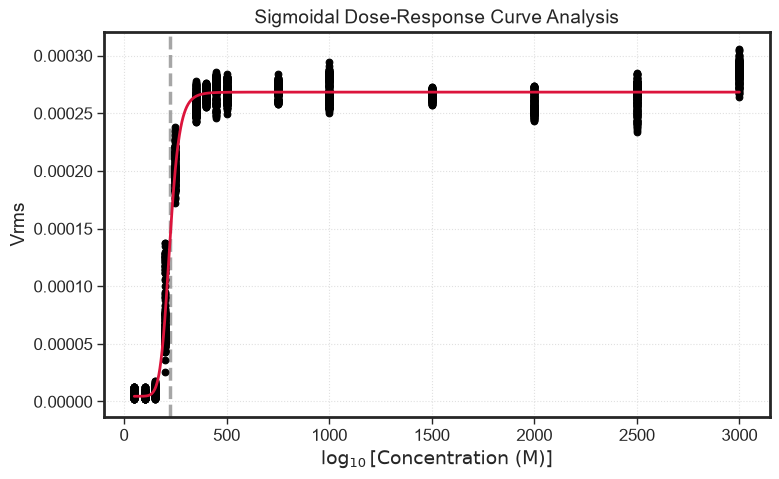

In [61]:
# Extract standard errors from the covariance matrix diagonal
perr = np.sqrt(np.diag(pcov))

bottom, top, log_ec50, hill_slope = popt
ec50_molar = 10**log_ec50

# 5. Calculate Goodness of Fit (R-squared)
# residuals = response - logistic4p(log_conc, *popt)
# ss_res = np.sum(residuals**2)
# ss_tot = np.sum((response - np.mean(response))**2)
# r_squared = 1 - (ss_res / ss_tot)

# Print Summary
print(f"--- Fit Results ---")
print(f"Bottom:     {bottom:.2f} ± {perr[0]:.2f}")
print(f"Top:        {top:.2f} ± {perr[1]:.2f}")
print(f"LogEC50:    {log_ec50:.2f} ± {perr[2]:.2f}")
print(f"EC50:       {ec50_molar:.2f} µA")
print(f"Hill Slope: {hill_slope:.2f} ± {perr[3]:.2f}")
#print(f"R² Score:   {r_squared:.4f}")

# 6. Visualization
x_dense = np.linspace(min(data[:,0]), max(data[:,0]),3000)
y_dense = sigmoid_log10(np.log10(x_dense), *popt)

plt.figure(figsize=(8, 5))
plt.scatter(data[:,0], data[:,1], color='black', label='Data Points', zorder=3)
plt.plot(x_dense, y_dense, color='crimson', linewidth=2, zorder = 4)#, label=f'4PL Fit ($R^2 = {r_squared:.3f}$)')

# Annotate EC50
plt.axvline(10**log_ec50, color='gray', linestyle='--', alpha=0.7, label=f'$EC_{{50}} = {ec50_molar:.2f}\\ \\mu A$')

plt.xlabel(r'$\log_{10}[\text{Concentration (M)}]$')
plt.ylabel('Vrms')
plt.title('Sigmoidal Dose-Response Curve Analysis')
#plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

[(0, 2)]
Plotting trace #s 0 to 100


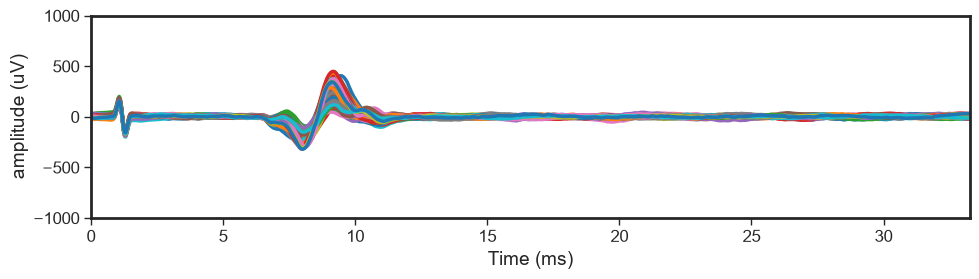

In [14]:
EMGf.plot_binned_traces(channel = 'Wav1 8', parameter = (0,2), bin = (0,100), y_lim = (-1e3,1e3))

In [ ]:
""" In rms, dim 1 = pulse #, dim 2 = channel 
For curve fitting:
X data = pulse amplitude
Y data = RMS based on calculation
"""
from collections import defaultdict
normalize = True
outlier_rejection = 'iqr'

rms = EMGf.pulse_RMS(parameters = stimDF.index.tolist(), channels = 'Wav1 8', window = (6,10), window_units = 'ms')

dataLIST = []
sigDCT = defaultdict(dict)

# Group parameters based off the first index of the stimulation parameter table multi-index. Assumes all parameters sharing a multi-index level 0 are from the same stimulation configuration
grouped_params = defaultdict(dict)
for key,pulse_rms in rms.items():
    idx = key[0]
    grouped_params[idx][key] = pulse_rms

for group, grouped_rms in grouped_params.items():

    if normalize:
        rms_max = np.max([np.max(grouped_rms[param]) for param in grouped_rms.keys()])
    
    for param, pulse_rms in grouped_rms.items():

        if outlier_rejection == 'iqr':
                # Interquartile rejection

                q1,q3 = np.percentile(pulse_rms, [25,75])
                iqr = q3 - q1

                lower_bound = q1 - 1.5 * iqr
                upper_bound = q3 + 1.5 * iqr

                outlier_mask = (pulse_rms < lower_bound) | (pulse_rms > upper_bound)
                clean_mask = (pulse_rms >= lower_bound) & (pulse_rms <= upper_bound)

                outliers = pulse_rms[outlier_mask]
                rms_d = pulse_rms[clean_mask]

        elif outlier_rejection == 'z':
                #Z-Score Method
                z_score = np.abs(scipy.stats.zscore(pulse_rms))

                outlier_mask = (z_score >= 3)
                clean_mask = (z_score < 3)

                outliers = (pulse_rms[outlier_mask])
                rms_d = (pulse_rms[clean_mask])

        else:
             rms_d = pulse_rms

        
    # Construct long format data array where one dim is pulse amplitude and the other is the Y values
    data = []
    for param in rms.keys():
        amp = np.abs(stimDF.loc[param, 'pulse amplitude A (μA)'])
        amp_array = np.ones((rms_d.shape[0],1)) * amp

        if normalize:
            data.append( np.column_stack([amp_array, rms_d/rms_max]))
        else:
            data.append( np.column_stack([amp_array, rms_d]))
        
    data = np.vstack(data)
    popt, pcov = sigmoid_fit(x = data[:,0], y = data[:,1], init_params = [1,1,150,0], log_transform = True, pad_min = True)
    dataLIST.append([group, list(grouped_rms.keys()), *popt])

    # Nested Dictionary
    sigDCT[group]['rms'] = grouped_rms
    sigDCT[group]['sigmoid coeffs.'] = popt
    sigDCT[group]['ED50 (uA)'] = 10**popt[2]

    """ Construct Return Data Structure
    Multi-index dataframe or nested dictionary??
    """
# DataFrame
columns = ['Multi-Index Level', 'Parameters', 'SigFit y-max', 'SigFit slope', 'SigFit ED50 (log10)', 'SigFit y-min']
sigDF = pd.DataFrame(data = dataLIST, columns = columns)
sigDF['ED50 (uA)'] = 10**sigDF['SigFit ED50 (log10)']